# Netflix × IMDb: Analysis and Charts

This notebook creates charts for the main findings of the project.
All data comes from the SQLite database `netflix.db`, created with the scripts in `scripts/` and `sql/`.

Connection to Database

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../netflix.db")
pd.read_sql("select count(*) as titles from netflix_clean", conn)

,titles
0,8807


## 1. Movies vs TV shows over time

How many movies and TV shows were added to Netflix each year?
Years before 2015 are skipped, because Netflix added very few titles then.

In [2]:
query = """
select
    year_added,
    count(case when "type" = 'Movie' then 1 end) as movies,
    count(case when "type" = 'TV Show' then 1 end) as tv_shows,
    round(100.0 * count(case when "type" = 'TV Show' then 1 end) / count(*), 1) as tv_show_pct,
    round(100.0 * count(case when "type" = 'Movie' then 1 end) / count(*), 1) as movies_pct
from netflix_clean
where year_added >= 2015
group by year_added
order by year_added
"""
df_years = pd.read_sql(query, conn)
df_years

,year_added,movies,tv_shows,tv_show_pct,movies_pct
0,2015,56,26,31.7,68.3
1,2016,253,176,41.0,59.0
2,2017,839,349,29.4,70.6
3,2018,1237,412,25.0,75.0
4,2019,1424,592,29.4,70.6
5,2020,1284,595,31.7,68.3
6,2021,993,505,33.7,66.3


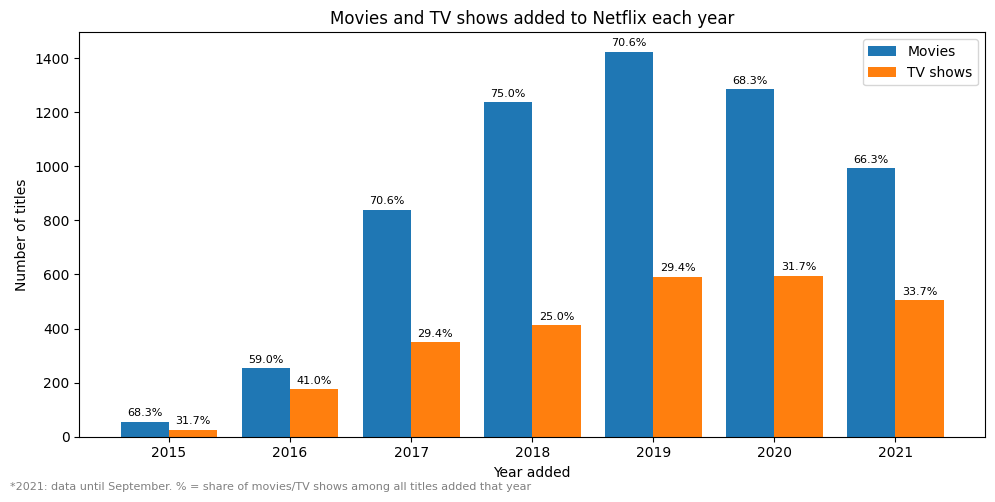

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

width = 0.4                       
x = df_years["year_added"]

# Movies on left, TV shows on right
ax.bar(x - width/2, df_years["movies"], width, label="Movies")
ax.bar(x + width/2, df_years["tv_shows"], width, label="TV shows")

# percent written above each bar
for _, row in df_years.iterrows():
    ax.text(row["year_added"] + width/2, row["tv_shows"] + 20,
            f"{row['tv_show_pct']}%", ha="center", fontsize=8)
    ax.text(row["year_added"] - width/2, row["movies"] + 20,
            f"{row['movies_pct']}%", ha="center", fontsize=8)

ax.set_title("Movies and TV shows added to Netflix each year")
ax.set_xlabel("Year added")
ax.set_ylabel("Number of titles")
ax.set_xticks(x)
ax.legend()

fig.text(0.01, 0.01, "*2021: data until September. % = share of movies/TV shows among all titles added that year",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/01_movies_vs_tv.png", dpi=150)
plt.show()

**Conclusion:**
Netflix started adding a lot of titles in 2016, and the most were added in 2019 (2,016).
Movies are always the majority, but the share of TV shows changes. It dropped from 41% in 2016
to 25% in 2018, and since then it grows every year, up to 33.7% in 2021.
The data ends in September 2021, so I compare percentages and not the number of titles.

## 2. New movies or older catalog?

How many of the movies added each year were new (released max 1 year before)?
Only movies are used, because for TV shows `release_year` is often the year of the latest season.

In [4]:
query = """
select year_added, count(title) as titles,
    round(100.0 * count(case when (year_added-release_year) <=1 then 1 end) / count(*), 1) as new_pct
from netflix_clean
where "type" = 'Movie' and year_added >= 2015
group by year_added
order by year_added;"""
df_movies = pd.read_sql(query, conn)
df_movies

,year_added,titles,new_pct
0,2015,56,89.3
1,2016,253,75.5
2,2017,839,62.8
3,2018,1237,49.0
4,2019,1424,45.9
5,2020,1284,46.0
6,2021,993,40.0


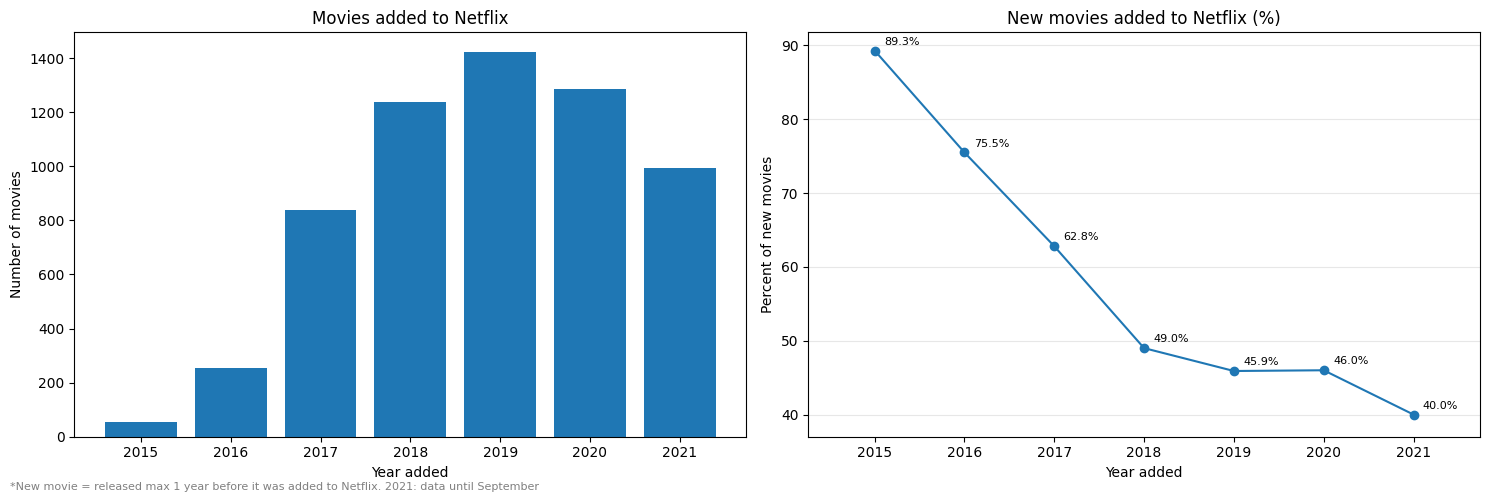

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharex=True)

x = df_movies["year_added"]

#First chart
ax1.bar(x, df_movies["titles"])
ax1.set_title("Movies added to Netflix")
ax1.set_ylabel("Number of movies")
ax1.set_xlabel("Year added")


#Second chart
ax2.plot(x,df_movies["new_pct"],marker="o")

for _, row in df_movies.iterrows():
    ax2.text(row["year_added"]+0.3, row["new_pct"] + 0.8,   
             f"{row['new_pct']}%", ha="center", fontsize=8)

ax2.set_ylim(37)
ax2.set_title("New movies added to Netflix (%)")
ax2.set_ylabel("Percent of new movies")
ax2.set_xlabel("Year added")
ax2.set_xticks(x)
ax2.grid(axis="y", alpha=0.3)

fig.text(0.01, 0.01, "*New movie = released max 1 year before it was added to Netflix. 2021: data until September",
         fontsize=8, color="gray")
plt.tight_layout()
plt.savefig("../images/02_new_movies.png", dpi=150)
plt.show()

**Conclusion:**
At the beginning almost all movies added to Netflix were new (89% in 2015).
Every year this share goes down, and in 2021 it was only 40%. So Netflix adds more and more
older movies. But this data is from 2021, so it only has titles that were still on Netflix then.
Some older movies added in the early years could already be removed, so the early years
may look "newer" than they really were.

## 3. Genres

Which genres have the best rated titles in IMDb?
Movies and TV shows are compared separately, because TV shows in general get higher ratings.
Only titles with at least 100 votes and genres with at least 50 titles are used.

In [6]:
query_movie = """select g.genre, count(n.title) as movies, round(avg(n.imdb_rating),2) as avg_rating
from netflix_clean n 
join netflix_genres g on n.show_id=g.show_id
where n.imdb_votes >= 100 and n."type" = 'Movie'
group by g.genre
having count(*)>=50
order by avg_rating desc;"""

query_show = """select g.genre, count(n.title) as tv_shows, round(avg(n.imdb_rating),2) as avg_rating
from netflix_clean n 
join netflix_genres g on n.show_id=g.show_id
where n.imdb_votes >= 100 and n."type" = 'TV Show'
group by g.genre
having count(*)>=50
order by avg_rating desc;"""

df_genres_movies = pd.read_sql(query_movie,conn)
df_genres_shows = pd.read_sql(query_show,conn)

combined_df = pd.concat([df_genres_movies, df_genres_shows], axis=1, keys=["Movies", "TV shows"])
combined_df

Movies                                     TV shows  \
                       genre movies avg_rating                      genre   
0             Classic Movies    108       7.34            Korean TV Shows   
1              Documentaries    645       6.93               Anime Series   
2                Cult Movies     65       6.84        Science & Nature TV   
3            Stand-Up Comedy    268       6.81           British TV Shows   
4              Sports Movies    181       6.58                  TV Dramas   
5                     Dramas   2044       6.42      TV Action & Adventure   
6           Music & Musicals    286       6.41                 Docuseries   
7               LGBTQ Movies     91       6.36             Crime TV Shows   
8         Independent Movies    684       6.30          Romantic TV Shows   
9       International Movies   2106       6.22              Teen TV Shows   
10           Romantic Movies    524       6.08        TV Sci-Fi & Fantasy   
11          Sci-Fi & Fantasy    217       6.01     International TV Shows   
12        Action & Adventure    751       6.00                TV Comedies   
13  Children & Family Movies    443       5.97               TV Mysteries   
14      Faith & Spirituality     51       5.96  Spanish-Language TV Shows   
15                  Comedies   1367       5.94                  TV Horror   
16                 Thrillers    518       5.90                 Reality TV   
17             Horror Movies    314       5.33                   Kids' TV   

                        
   tv_shows avg_rating  
0       102       7.47  
1       138       7.39  
2        71       7.37  
3       193       7.33  
4       569       7.32  
5       141       7.32  
6       295       7.32  
7       394       7.27  
8       243       7.22  
9        63       7.20  
10       71       7.20  
11      950       7.19  
12      446       7.09  
13       91       7.07  
14      128       6.96  
15       63       6.90  
16      201       6.58  
17      318       6.58

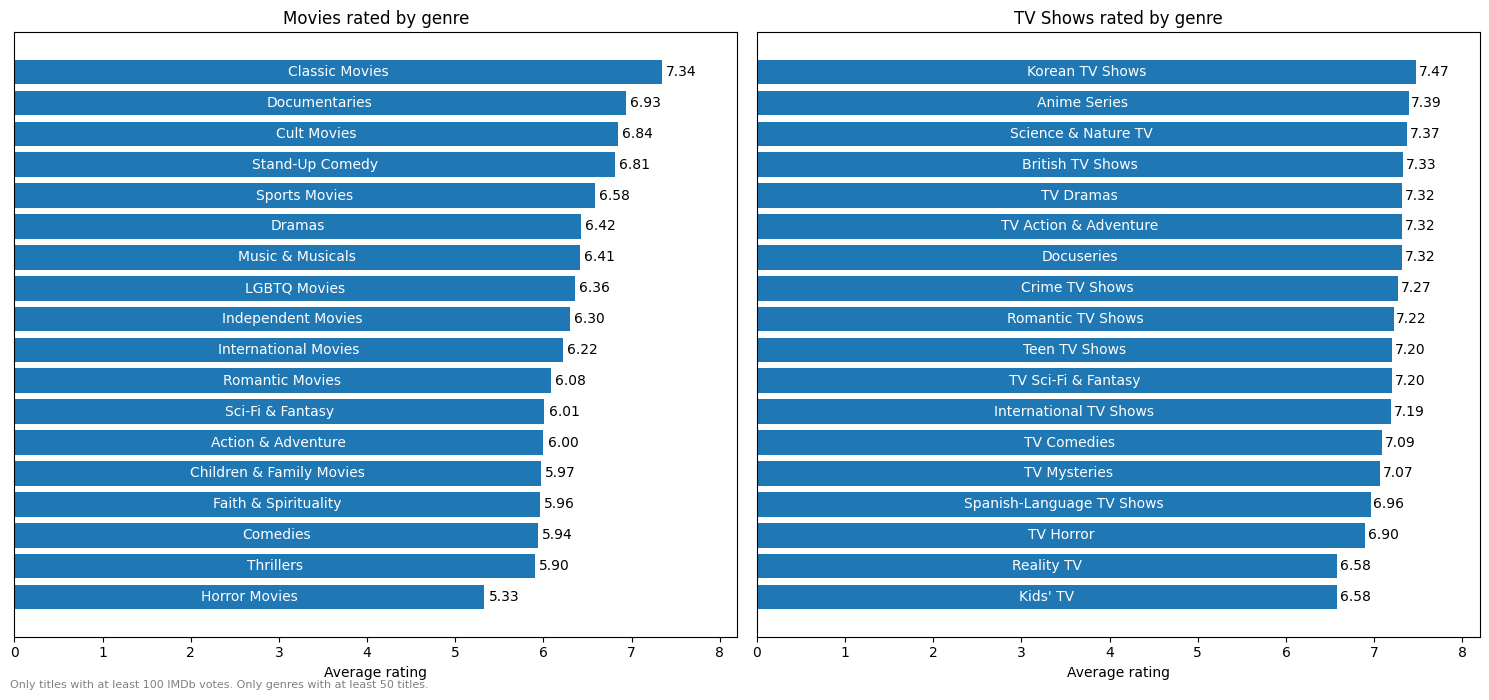

In [7]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(15, 7), sharex=True)

x1 = df_genres_movies["genre"]
x2 = df_genres_shows["genre"]

#First chart
bars1 = ax1.barh(x1, df_genres_movies["avg_rating"])
ax1.set_title("Movies rated by genre")
ax1.set_ylabel("Genre")
ax1.set_xlabel("Average rating")
ax1.bar_label(bars1,labels = x1, label_type ='center',color='white')
ax1.bar_label(bars1, label_type ='edge',color='black',padding=3,fmt="%.2f")
ax1.yaxis.set_visible(False)
ax1.invert_yaxis()
ax1.set_xlim(0, 8.2)

#Second chart
bars2 = ax2.barh(x2, df_genres_shows["avg_rating"])
ax2.set_title("TV Shows rated by genre")
ax2.set_ylabel("Genre")
ax2.set_xlabel("Average rating")
ax2.bar_label(bars2,labels = x2, label_type ='center',color='white',)
ax2.bar_label(bars2, label_type ='edge',color='black',padding=2,fmt="%.2f")
ax2.yaxis.set_visible(False)
ax2.invert_yaxis()

fig.text(0.01, 0.01, "Only titles with at least 100 IMDb votes. Only genres with at least 50 titles.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/03_genres.png", dpi=150)
plt.show()

**Conclusion:**
TV shows get higher ratings than movies. Even the worst rated TV genres (6.58)
are on the level of good movie genres. For movies, the best rated are Classic Movies (7.34),
Documentaries and Stand-Up Comedy, and the worst are Horror Movies (5.33), Thrillers and Comedies.
Classic movies are probably so high because Netflix only adds old movies that people still like.
For TV shows, Korean TV Shows (7.47) and Anime Series (7.39) are at the top.

## 4. Countries

Which countries have the best rated titles on Netflix?
Only titles with at least 100 votes and countries with at least 20 titles are used.

In [8]:
query = """select c.country,count(n.title) as titles, 
        count(case when n."type"='Movie' then 1 end)as movies,
        round(avg(case when n."type" = 'Movie' then n.imdb_rating end),2) as movie_avg_rating,
        count(case when n."type"='TV Show' then 1 end)as tv_shows,
        round(avg(case when n."type" = 'TV Show' then n.imdb_rating end),2)as tv_show_avg_rating,
        round(avg(n.imdb_rating),2)as all_ratings
from netflix_clean n join netflix_countries c on n.show_id=c.show_id
where n.imdb_votes >= 100
group by c.country
having count(*) >= 20
order by all_ratings desc;"""

df_countries = pd.read_sql(query,conn)
df_countries

,country,titles,movies,movie_avg_rating,tv_shows,tv_show_avg_rating,all_ratings
0,South Korea,181,50,6.29,131,7.48,7.15
1,Japan,250,85,6.49,165,7.36,7.07
2,Ireland,43,30,6.66,13,7.72,6.98
3,New Zealand,29,21,6.97,8,6.75,6.91
4,Israel,27,18,6.57,9,7.56,6.90
5,Pakistan,20,16,6.50,4,8.20,6.84
6,Colombia,32,10,5.83,22,7.28,6.83
7,United Kingdom,686,472,6.57,214,7.37,6.82
8,Taiwan,55,19,6.38,36,7.05,6.82
9,Denmark,40,28,6.66,12,7.14,6.81


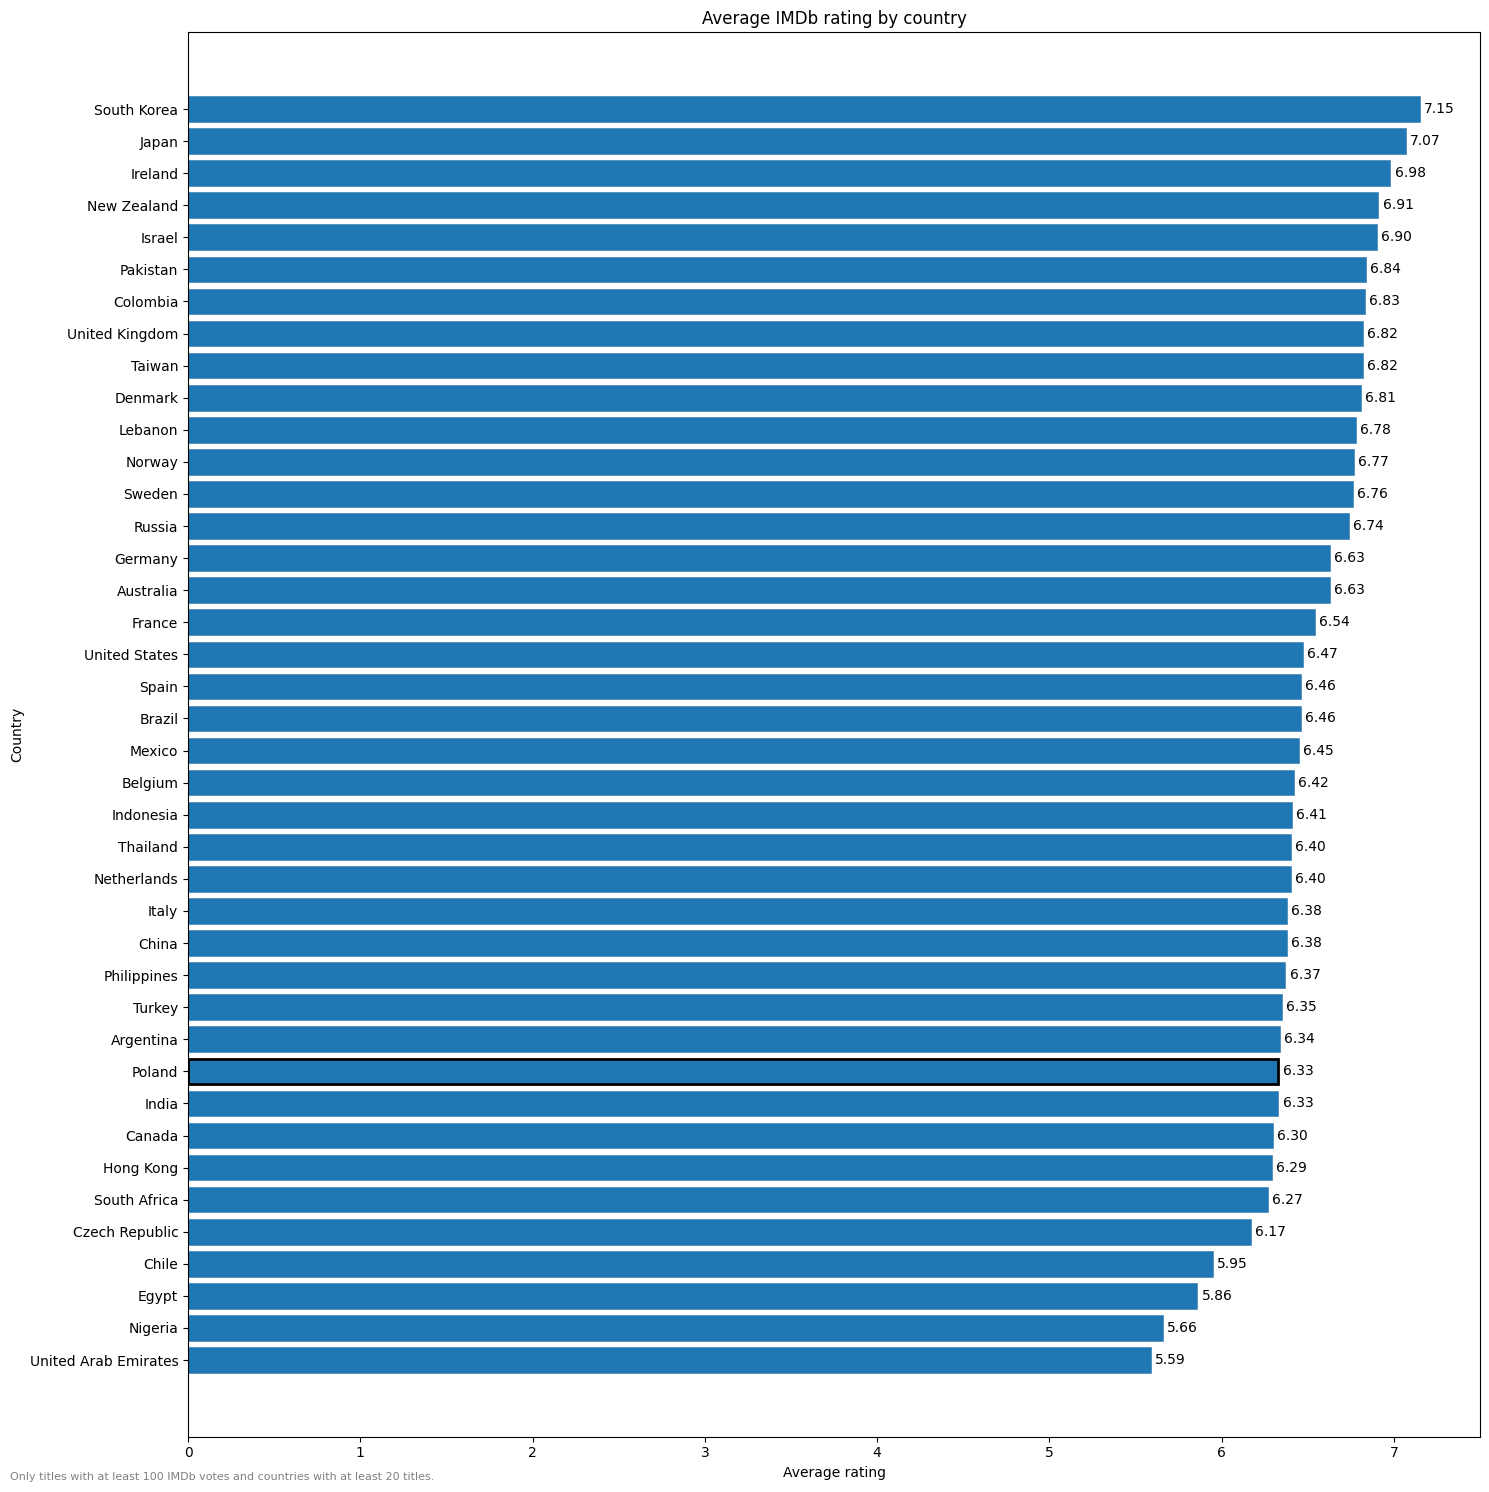

In [ ]:
fig,ax = plt.subplots(figsize=(15, 15))

x = df_countries["country"]
y= df_countries["all_ratings"]
bar_colors =['black' if v == "Poland" else "steelblue" for v in x]
bar_linewidth =[2 if v == "Poland" else 0.5 for v in x]

bars = ax.barh(x, y, edgecolor=bar_colors,linewidth=bar_linewidth)
ax.set_title("Average IMDb rating by country")
ax.set_ylabel("Country")
ax.set_xlabel("Average rating")
ax.bar_label(bars, label_type ='edge',color='black',padding=3,fmt="%.2f")
ax.invert_yaxis()
ax.set_xlim(0, 7.5)


fig.text(0.01, 0.01, "Only titles with at least 100 IMDb votes and countries with at least 20 titles.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/04_countries_a.png", dpi=150)
plt.show()

As we saw earlier, South Korea is probably high because of its TV shows (dramas),
and Japan because of anime. Let's see how movies and TV shows are rated
in a few of the best rated countries and in Poland.

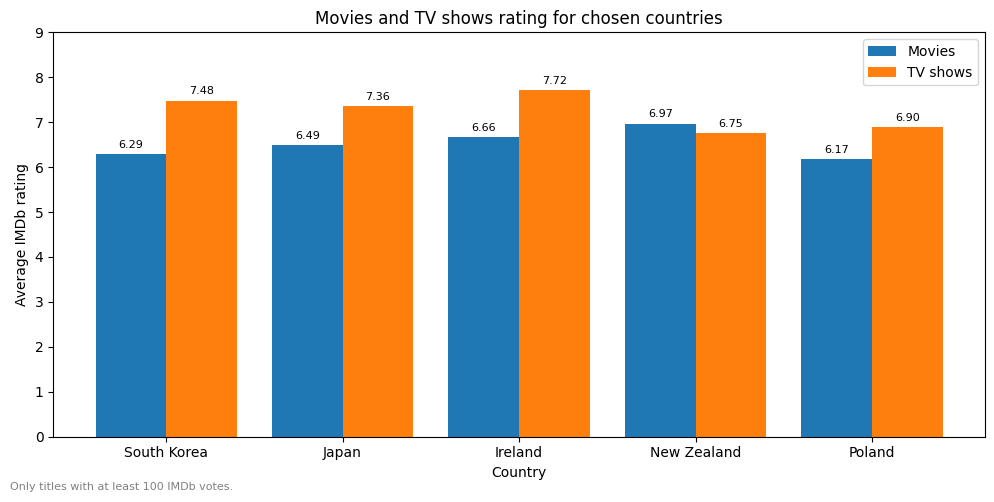

In [10]:
import numpy as np

fig, ax = plt.subplots(figsize=(10, 5))

width = 0.4
df_selected = df_countries[df_countries["country"].isin(["South Korea", "Japan", "Ireland", "New Zealand", "Poland"])]
x = np.arange(len(df_selected))                     

# Movies on left, TV shows on right
bars1 = ax.bar(x - width/2, df_selected["movie_avg_rating"], width, label="Movies")      
bars2 = ax.bar(x + width/2, df_selected["tv_show_avg_rating"], width, label="TV shows")  

# values on top of bars with bar_label 
ax.bar_label(bars1, fmt="%.2f", padding=3, fontsize=8)
ax.bar_label(bars2, fmt="%.2f", padding=3, fontsize=8)

ax.set_title("Movies and TV shows rating for chosen countries")
ax.set_xlabel("Country")
ax.set_ylabel("Average IMDb rating")
ax.set_xticks(x)
ax.set_xticklabels(df_selected["country"])         
ax.set_ylim(0, 9)                                    
ax.legend()

fig.text(0.01, 0.01, "Only titles with at least 100 IMDb votes.",   
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/04_countries_b.png", dpi=150)
plt.show()

**Conclusion:** 
South Korea and Japan have the best rated titles, but mostly because of their TV shows.
Korean TV shows have 7.48, but Korean movies only 6.29. New Zealand is the only one
of these countries where movies are rated higher than TV shows. Poland is 31st of 40 countries
with 6.33, and like most countries its TV shows (6.90) are rated higher than movies (6.17).
Some groups are small (for example only 8 TV shows from Poland), so these numbers are not very reliable.

## 5. Movie duration

Are movies getting shorter? Average duration of movies by decade of release.

In [11]:
query_duration = """select 
    (release_year/10)*10 as decade,
    count(*) as movies,
    round(avg(duration_min),2) as avg_duration
from netflix_clean
where "type" = 'Movie'
group by decade
order by decade;
"""

df_duration = pd.read_sql(query_duration,conn)
df_duration

,decade,movies,avg_duration
0,1940,13,51.38
1,1950,11,107.09
2,1960,23,147.61
3,1970,66,119.24
4,1980,122,116.23
5,1990,241,113.84
6,2000,677,112.11
7,2010,4184,96.91
8,2020,794,93.64


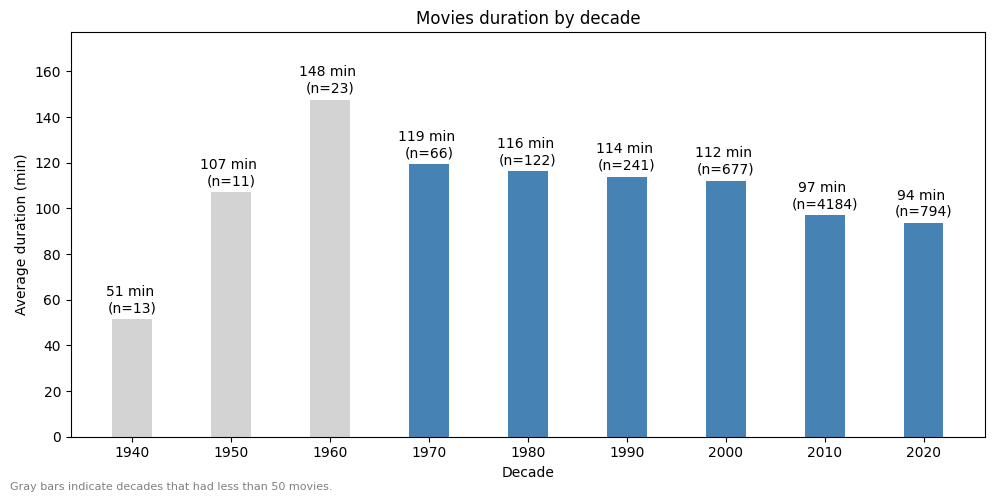

In [12]:
fig,ax = plt.subplots(figsize=(10, 5))

x = df_duration["decade"]
y = df_duration["avg_duration"]

colors = ["lightgray" if m < 50 else "steelblue" for m in df_duration["movies"] ]
bars = ax.bar(x,y,color=colors,width=4)

ax.bar_label(bars,labels = [f"{m:.0f} min \n(n={n})" for m,n in zip(df_duration["avg_duration"],df_duration["movies"])],
            label_type ='edge',padding=3)

ax.set_title("Movies duration by decade")
ax.set_xlabel("Decade")
ax.set_ylabel("Average duration (min)")
ax.set_xticks(x)
ax.set_ylim(0,y.max() * 1.2)                                    

fig.text(0.01, 0.01, "Gray bars indicate decades that had less than 50 movies.",   
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/05_duration.png", dpi=150)
plt.show()

**Conclusion:**
Movies are getting shorter. In the 1970s a movie was on average 119 minutes long,
and in the 2020s only 94 minutes. The biggest drop is between the 2000s and the 2010s.
The gray decades have very few movies, so I don't trust their averages.
Part of the drop may come from more stand-ups, documentaries and kids' content on Netflix,
not only from movies being shorter.

## 6. TV show seasons

How many seasons do TV shows on Netflix have, and are shows with more seasons rated higher?

In [13]:
query_seasons="""with shows as(
    select imdb_rating,imdb_votes,
        case when seasons>=5 then '5+'
            else cast(seasons as text)
        end as seasons_group
    from netflix_clean
    where "type" = 'TV Show'
)
select seasons_group, count(*) as tv_shows,
    round(100.0 * count(*) / sum(count(*)) over (), 1) as pct,
    round(avg(case when imdb_votes >= 100 then imdb_rating end), 2) as avg_rating
from shows
group by seasons_group
order by seasons_group;"""

query_one_season = """select
    c.country,
    count(*) as tv_shows,
    round(100.0 * count(case when n.seasons = 1 then 1 end) / count(*), 1) as one_season_pct
from netflix_clean n
join netflix_countries c on n.show_id = c.show_id
where n."type" = 'TV Show'
  and c.country in ('South Korea', 'Japan', 'United States', 'United Kingdom')
group by c.country
order by one_season_pct desc;"""

df_seasons = pd.read_sql(query_seasons,conn)
df_one_season  = pd.read_sql(query_one_season,conn)


combined_df = pd.concat([df_seasons, df_one_season], axis=1, keys=["seasons", "one_season"])
combined_df

seasons                                one_season           \
  seasons_group tv_shows   pct avg_rating         country tv_shows   
0             1     1793  67.0       7.03     South Korea    170.0   
1             2      425  15.9       6.99           Japan    199.0   
2             3      199   7.4       7.39  United Kingdom    272.0   
3             4       95   3.6       7.27   United States    938.0   
4            5+      164   6.1       7.81             NaN      NaN   

                  
  one_season_pct  
0           83.5  
1           64.8  
2           60.3  
3           53.0  
4            NaN

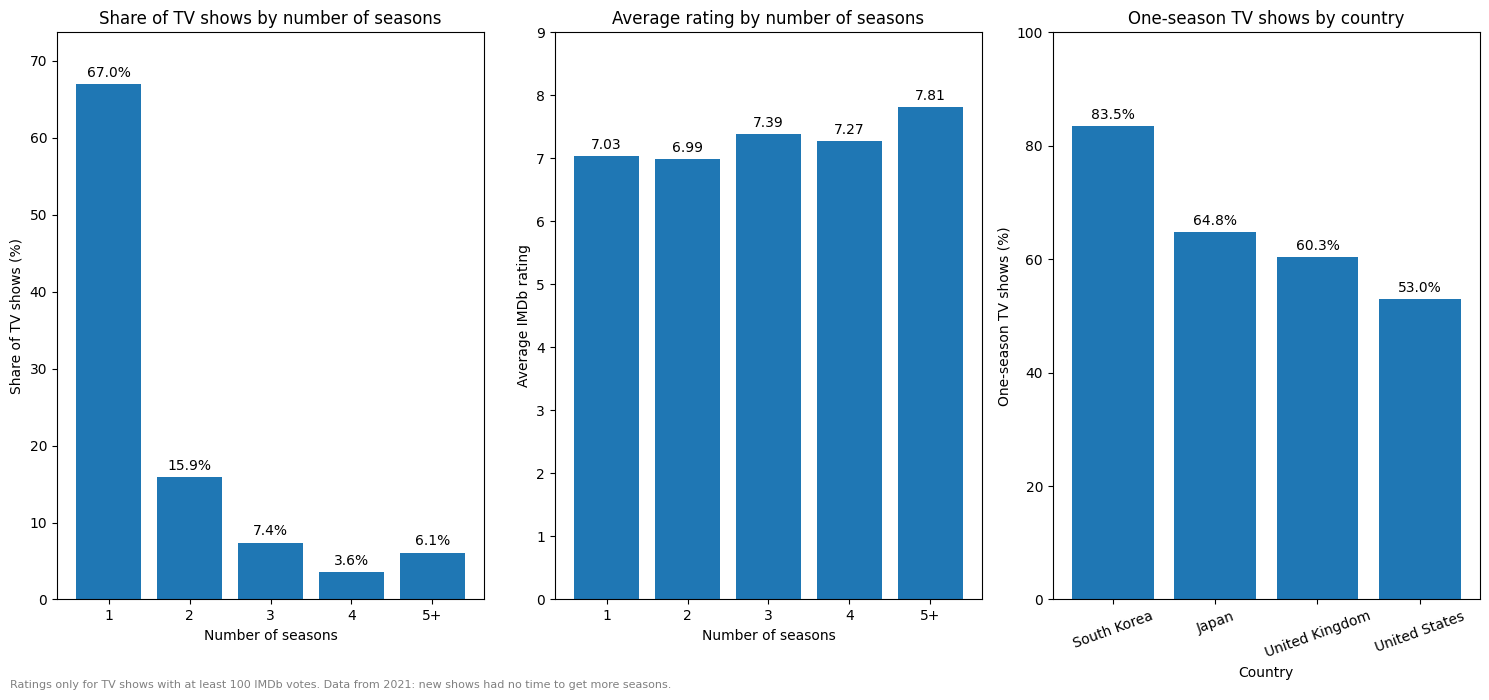

In [14]:
fig, (ax1, ax2,ax3) = plt.subplots(ncols=3, figsize=(15, 7))

x1 = df_seasons["seasons_group"]
x3 =df_one_season["country"]
y1 = df_seasons["pct"]
y2 = df_seasons["avg_rating"]
y3 = df_one_season["one_season_pct"]


#First chart
bars=ax1.bar(x1, y1)
ax1.set_title("Share of TV shows by number of seasons")
ax1.set_xlabel("Number of seasons")
ax1.set_ylabel("Share of TV shows (%)")                          
ax1.bar_label(bars, labels=[f"{v}%" for v in y1], padding=3) 
ax1.set_ylim(0, y1.max() * 1.1)

#Second chart
bars2 = ax2.bar(x1, y2)
ax2.set_title("Average rating by number of seasons")
ax2.set_ylabel("Average IMDb rating")
ax2.set_xlabel("Number of seasons")
ax2.bar_label(bars2, fmt="%.2f", padding=3)
ax2.set_ylim(0, 9)

#Third chart
bars3 = ax3.bar(x3, y3)
ax3.set_title("One-season TV shows by country")
ax3.set_ylabel("One-season TV shows (%)")
ax3.set_xlabel("Country")
ax3.bar_label(bars3, labels=[f"{v}%" for v in y3], padding=3)
ax3.set_ylim(0, 100)
ax3.tick_params(axis="x", rotation=20)                          


fig.text(0.01, 0.01,
         "Ratings only for TV shows with at least 100 IMDb votes. "
         "Data from 2021: new shows had no time to get more seasons.",
         fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("../images/06_seasons.png", dpi=150)
plt.show()

**Conclusion:**
Two thirds of TV shows on Netflix (67%) have only 1 season. Shows with more seasons
have higher ratings, from about 7.0 for 1-2 seasons up to 7.81 for 5+. Probably good shows
get more seasons and weak shows are cancelled early. One-season shows are most common
in South Korea (83.5%), because Korean dramas are usually planned as one season.
But even in the US more than half of the shows have only 1 season.
The data is from 2021, so new shows had no time to get more seasons.

## Summary

Netflix added most of its titles between 2017 and 2021, and since 2018 the share of TV shows grows.
It also adds more and more older movies, not only new ones. TV shows get higher ratings than movies,
and the best rated titles come from South Korea and Japan, mostly thanks to their TV shows.
Poland is in the lower half of the ranking. Movies on Netflix are getting shorter,
and most TV shows have only one season, but the ones with more seasons are rated higher.